# Figure 4, Panel B

Scatterplot of expression log2FCs Dex/Veh vs IFNg/Veh, including only the 500 genes that are significantly induced by either stimulus. Points that are significantly induced by *both* stimuli are colored black. Plot is annotated with Pearson r (correlation of log2FCs)

*Output: panelB_stim_orthogonality.pdf*

# Setup

In [1]:
library(tidyverse)
library(RColorBrewer)
library(here)
here::i_am("figures/Figure4/Panel_B/PanelB_ifn_v_dex.ipynb")

theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=20)))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/Figure4/Panel_B

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         RColorBrewer_1.1-3 lubridate_1.9.4    forcats_1.0.0     
 [5] stringr_1.5.1      dplyr_1.1.4        purrr_1.0.2        readr_2.1.5       
 [9] tidyr_1.3.1        tibble_3.2.1       ggplot2_3.5.2      tidyverse_2.0.0   

loaded via a namespace (and not attached):
 [1] pi

# Load data (differential expression analysis results)

In [3]:
ifn_1h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus",
    "IFNy_1h_DEGs.tsv"
  ),
  sep = "\t"
)

ifn_6h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus",
    "IFNy_6h_DEGs.tsv"
  ),
  sep = "\t"
)

dex_1h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus",
    "Dex_1h_DEGs.tsv"
  ),
  sep = "\t"
)

dex_6h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus",
    "Dex_6h_DEGs.tsv"
  ),
  sep = "\t"
)

#determine set of genes DE with either stimulus (at any timepoint)
all_DEGs <- which(ifn_1h$change == "up" | ifn_6h$change == "up" | dex_1h$change == "up" | dex_6h$change == "up")

# Generate plot

Saving 7 x 7 in image


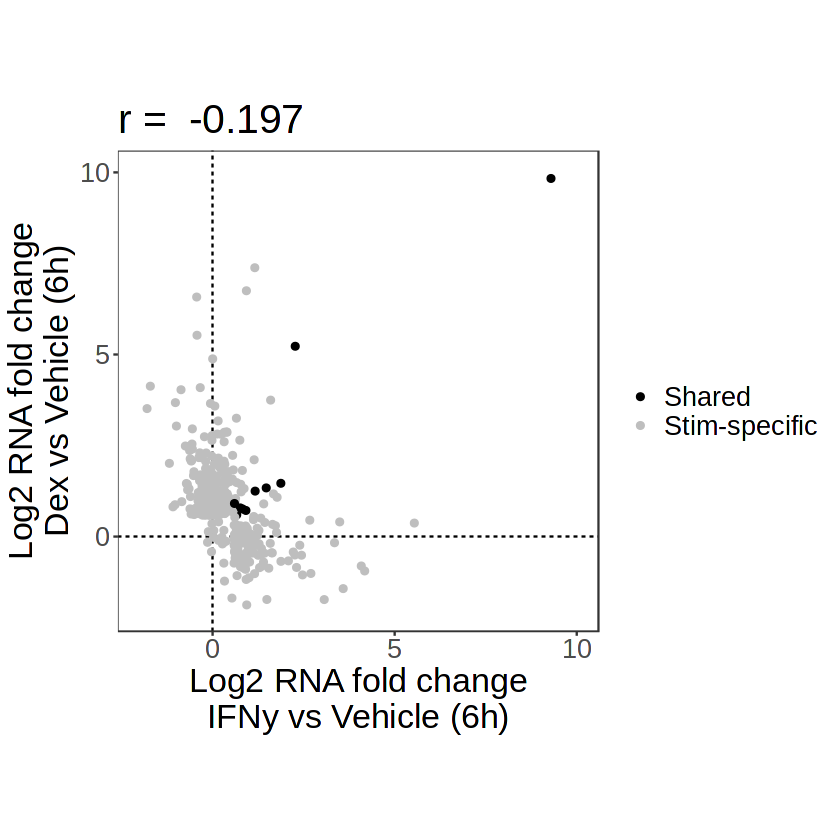

In [8]:
#calculate Pearson correlation for Dex and IFNg log2FCs at inducible genes
r <- cor.test(ifn_6h[all_DEGs,"log2FoldChange"], dex_6h[all_DEGs,"log2FoldChange"])$estimate

#plot
ggplot(NULL, aes(x=ifn_6h[all_DEGs,"log2FoldChange",], y=dex_6h[all_DEGs,"log2FoldChange",])) +
    geom_vline(xintercept=0,linetype=2) + 
    geom_hline(yintercept=0,linetype=2) + 
    coord_fixed() + 
    geom_point(aes(color=
                   case_when(ifn_6h[all_DEGs,"change"]=="up" & dex_6h[all_DEGs,"change"] =="up" ~ "Shared", 
                            TRUE ~ "Stim-specific"))) +
    scale_color_manual(values=c("Shared"="black","Stim-specific"="grey"), name="") +
    xlab("Log2 RNA fold change\nIFNy vs Vehicle (6h)") +
    ylab("Log2 RNA fold change\nDex vs Vehicle (6h)") +
    ggtitle(paste("r = ", format(r,digits=3))) +
    scale_x_continuous(limits=c(-2,10),breaks=seq(0,10,by=5)) + scale_y_continuous(limits=c(-2,10),breaks=seq(0,10,by=5))
ggsave("panelB_stim_orthogonality.pdf")